<a href="https://colab.research.google.com/github/jelianeys21/procesamiento-imagenes/blob/main/solucion_pc1_gris-imagenes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

PREGUNTA 1

In [ ]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pyplot as plt

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


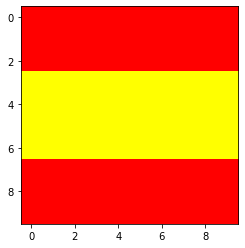

In [ ]:
# np.tile(np.array([255, 0, 0]), (3, 1))
# Inicializar la variable
España = np.zeros((10,10,3))
# Imagen a color esta formado por RGB
R = np.array([255, 0, 0])
G = np.array([255, 255, 0])
B = np.array([255, 0, 0])
# Eje X
España[:][:][0:3] = R
# Eje Y
España[:][:][3:7] = G
# Eje Z
España[:][:][7:] = B
plt.imshow(España)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


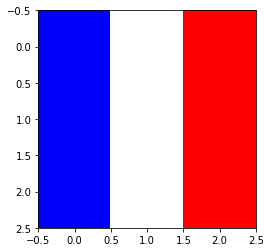

In [ ]:
Francia = np.zeros((3,3,3))
# Imagen a color esta formado por RGB
R = np.array([0, 0, 255])
G = np.array([255, 255, 255])
B = np.array([255, 0, 0])
# Eje X
Francia[:][:][0] = R
# Eje Y
Francia[:][:][1] = G
# Eje Z
Francia[:][:][2] = B
plt.imshow(Francia.transpose(1, 0, 2))

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


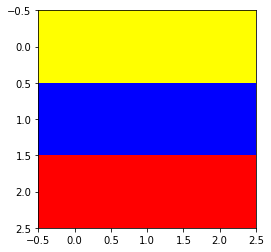

In [ ]:
Ecuador = np.zeros((3,3,3))
# Imagen a color esta formado por RGB
R = np.array([255, 255, 0])
G = np.array([0, 0, 255])
B = np.array([255, 0, 0])
# Eje X
Ecuador[:][:][0] = R
# Eje Y
Ecuador[:][:][1] = G
# Eje Z
Ecuador[:][:][2] = B
plt.imshow(Ecuador)

PREGUNTA 2

In [ ]:
def convertRGB2Gray2Binary(imagen, umbral):
  d = len(imagen.shape)
  if d == 3:
    R = imagen[:,:,0]
    G = imagen[:,:,1]
    B = imagen[:,:,2]
    imagen_gris = 0.299*R + 0.587*G + 0.114*B
    imagen_binaria = imagen_gris > umbral
    return (imagen_gris.astype(np.uint8), imagen_binaria.astype(np.ubyte))
  else:
    imagen_binaria = imagen > umbral
    return imagen_binaria.astype(np.ubyte)

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 23648  100 23648    0     0   262k      0 --:--:-- --:--:-- --:--:--  262k
(400, 800, 3)


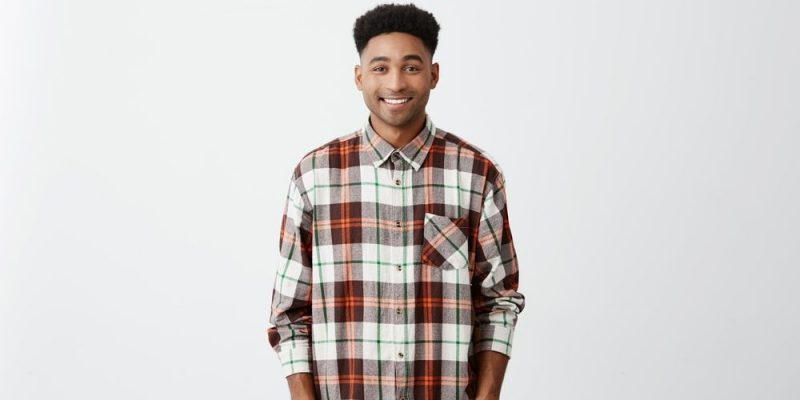

In [ ]:
!curl -o imagen https://concepto.de/wp-content/uploads/2018/08/persona-e1533759204552.jpg
persona = cv2.imread("imagen")
print(persona.shape)
cv2_imshow(persona)

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 77311  100 77311    0     0   567k      0 --:--:-- --:--:-- --:--:--  567k
(640, 960)


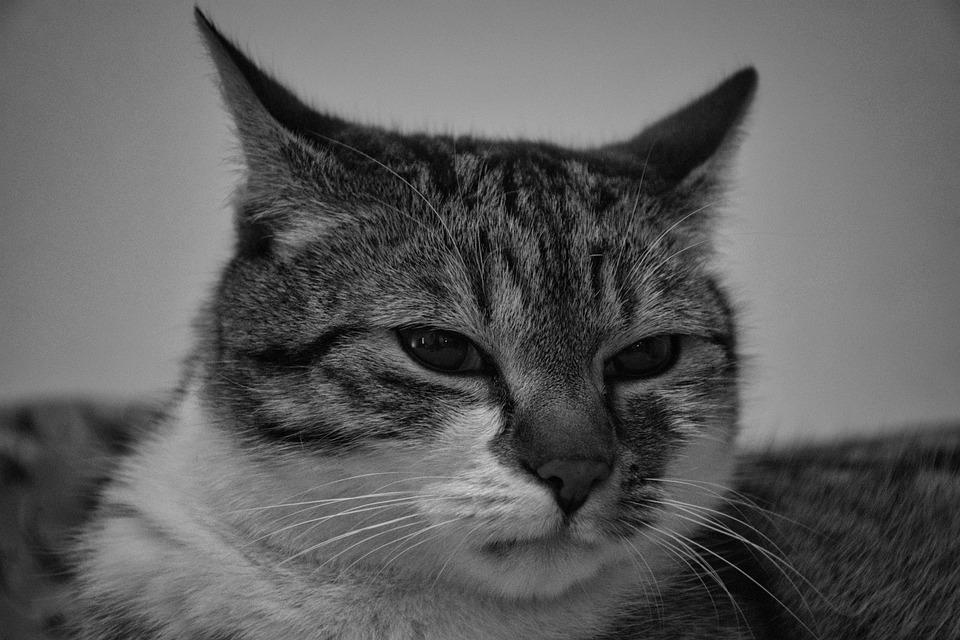

(640, 960, 3)


In [ ]:
!curl -o machu https://cdn.pixabay.com/photo/2020/05/10/00/08/grayscale-5151809_960_720.jpg
machu_picchu = cv2.imread("machu")
machu_picchu_gris = cv2.cvtColor(machu_picchu, cv2.COLOR_BGR2GRAY)
print(machu_picchu_gris.shape)
cv2_imshow(machu_picchu)
print(machu_picchu.shape)

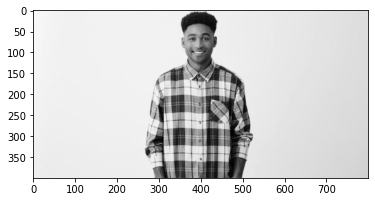

In [ ]:
(igris, ibinaria) =  convertRGB2Gray2Binary(persona, 120)
plt.imshow(igris)
plt.gray()

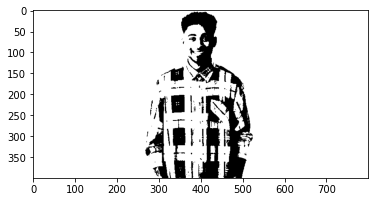

In [ ]:
plt.imshow(ibinaria)

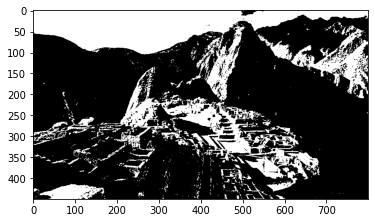

In [ ]:
ibinario2 = convertRGB2Gray2Binary(machu_picchu_gris, 120)
plt.imshow(ibinario2)

PREGUNTA 3

In [ ]:
def cortar_imagen(imagen_gris, inicio_x, inicio_y, alto, ancho):
  (f, c) = imagen_gris.shape
  d = len(imagen_gris.shape)
  if d == 2:
    imagen_cortada = imagen_gris[inicio_y:inicio_y+alto, inicio_x:inicio_x+ancho]
    return imagen_cortada.astype(np.uint8)

def agregar_marcos(imagen_gris, alto, ancho):
  (f, c) = imagen_gris.shape
  d = len(imagen_gris.shape)
  if d == 2:
    nueva_imagen = np.zeros((f+alto*2, c+ancho*2))
    nueva_imagen[alto:-alto,ancho:-ancho] = imagen_gris

    return nueva_imagen.astype(np.uint8)

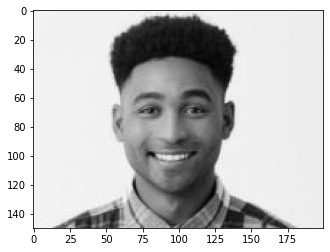

In [ ]:
persona_cortada = cortar_imagen(igris, 300, 0, 150, 200)
plt.imshow(persona_cortada)

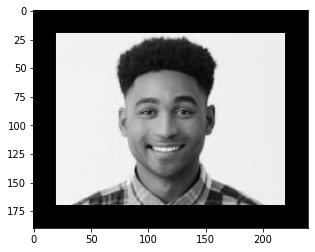

In [ ]:
persona_marcos = agregar_marcos(persona_cortada, 20, 20)
plt.imshow(persona_marcos)

PREGUNTA 4

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 90136  100 90136    0     0   633k      0 --:--:-- --:--:-- --:--:--  633k
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 73631  100 73631    0     0   425k      0 --:--:-- --:--:-- --:--:--  422k


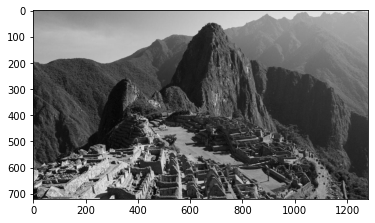

In [ ]:

!curl -o machu https://raw.githubusercontent.com/giancarlo92/pdi_g1/main/imagenes/solucion_pc1/machu-picchu.jpg
!curl -o machu2 https://raw.githubusercontent.com/giancarlo92/pdi_g1/main/imagenes/solucion_pc1/machu-picchu-cortado.jpg
imagen_machu_picchu = cv2.imread("machu")
machu_picchu_cortado = cv2.imread("machu2")
(f, c, _) = imagen_machu_picchu.shape
round(c/2)
imagen_machu_picchu[:, round(c/2)-1:] = machu_picchu_cortado
plt.imshow(imagen_machu_picchu)